# Taller práctico – Machine Learning
## Predicción de aprobación de préstamos

**Dataset:** [Loan Prediction Problem Dataset (Kaggle)](https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset), archivo `train_u6lujuX_CVtuZ9i.csv` (614 solicitudes de crédito).

**Estudiante:** Juan Andrés
**Entrega:** 11 de noviembre de 2026

**Flujo del taller:** comprensión del problema → EDA → preparación de datos → modelado (2 modelos) → evaluación → interpretación.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # semilla fija: los resultados son reproducibles

## Parte 1 – Comprensión del problema

**Variable objetivo (target):** `Loan_Status`, que indica si la solicitud de crédito fue **aprobada (`Y`)** o **rechazada (`N`)**.

**Contexto del problema:** el dataset proviene de una compañía de créditos de vivienda que atiende zonas urbanas, semiurbanas y rurales. Cuando una persona solicita un crédito, la compañía valida si cumple los requisitos para recibirlo. Cada fila es una solicitud, con datos del solicitante (género, estado civil, dependientes, educación, tipo de empleo, ingresos propios y del codeudor), del crédito (monto y plazo), su historial crediticio y la zona de la propiedad.

**Objetivo de negocio:** predecir si una solicitud será aprobada o no. Es un problema de **clasificación binaria supervisada**. Un modelo así serviría como filtro inicial para agilizar el estudio de solicitudes, nunca para reemplazar la decisión final de un analista de crédito.

## Parte 2 – Exploración de datos (EDA básica)

In [2]:
DATA_PATH = Path("data") / "train_u6lujuX_CVtuZ9i.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No encuentro {DATA_PATH.resolve()}. Abre la carpeta del proyecto en VS Code "
        "(que 'data/' quede junto al notebook) y vuelve a ejecutar."
    )

df = pd.read_csv(DATA_PATH)
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Filas: 614 | Columnas: 13


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


### 2.1 Valores nulos

In [3]:
nulos = df.isna().sum().to_frame("nulos")
nulos["% del total"] = (nulos["nulos"] / len(df) * 100).round(2)
nulos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)
print(f"Valores nulos totales: {int(df.isna().sum().sum())} en {len(nulos)} columnas")
nulos

Valores nulos totales: 149 en 7 columnas


,nulos,% del total
Credit_History,50,8.14
Self_Employed,32,5.21
LoanAmount,22,3.58
Dependents,15,2.44
Loan_Amount_Term,14,2.28
Gender,13,2.12
Married,3,0.49


### 2.2 Variables numéricas y categóricas, y variable objetivo

In [4]:
TARGET = "Loan_Status"

features = df.drop(columns=["Loan_ID", TARGET])   # Loan_ID es solo un identificador
num_cols = features.select_dtypes(include="number").columns.tolist()
cat_cols = features.select_dtypes(exclude="number").columns.tolist()

print("Variable objetivo :", TARGET)
print("Numéricas         :", num_cols)
print("Categóricas       :", cat_cols)
print("Identificador     : Loan_ID (se descarta, no aporta información)")

Variable objetivo : Loan_Status
Numéricas         : ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categóricas       : ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
Identificador     : Loan_ID (se descarta, no aporta información)


In [5]:
df[num_cols].describe().round(1)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.0,614.0,592.0,600.0,564.0
mean,5403.5,1621.2,146.4,342.0,0.8
std,6109.0,2926.2,85.6,65.1,0.4
min,150.0,0.0,9.0,12.0,0.0
25%,2877.5,0.0,100.0,360.0,1.0
50%,3812.5,1188.5,128.0,360.0,1.0
75%,5795.0,2297.2,168.0,360.0,1.0
max,81000.0,41667.0,700.0,480.0,1.0


In [6]:
print("Distribución de la variable objetivo:")
conteo = df[TARGET].value_counts()
pd.DataFrame({"solicitudes": conteo, "%": (conteo / len(df) * 100).round(1)})

Distribución de la variable objetivo:


,solicitudes,%
Loan_Status,,
Y,422,68.7
N,192,31.3


**Observaciones:**
- `Credit_History` está codificada como número (0 / 1) pero en realidad es una variable binaria: 1 = tiene historial crediticio que cumple las pautas, 0 = no.
- `Dependents` incluye el valor `3+`, por eso se trata como categórica.
- La clase `Y` (aprobado) es mayoritaria: el dataset está **desbalanceado**, así que la *accuracy* sola puede engañar. Más adelante se compara contra un modelo "base" que siempre predice `Y`.

### 2.3 Gráficos

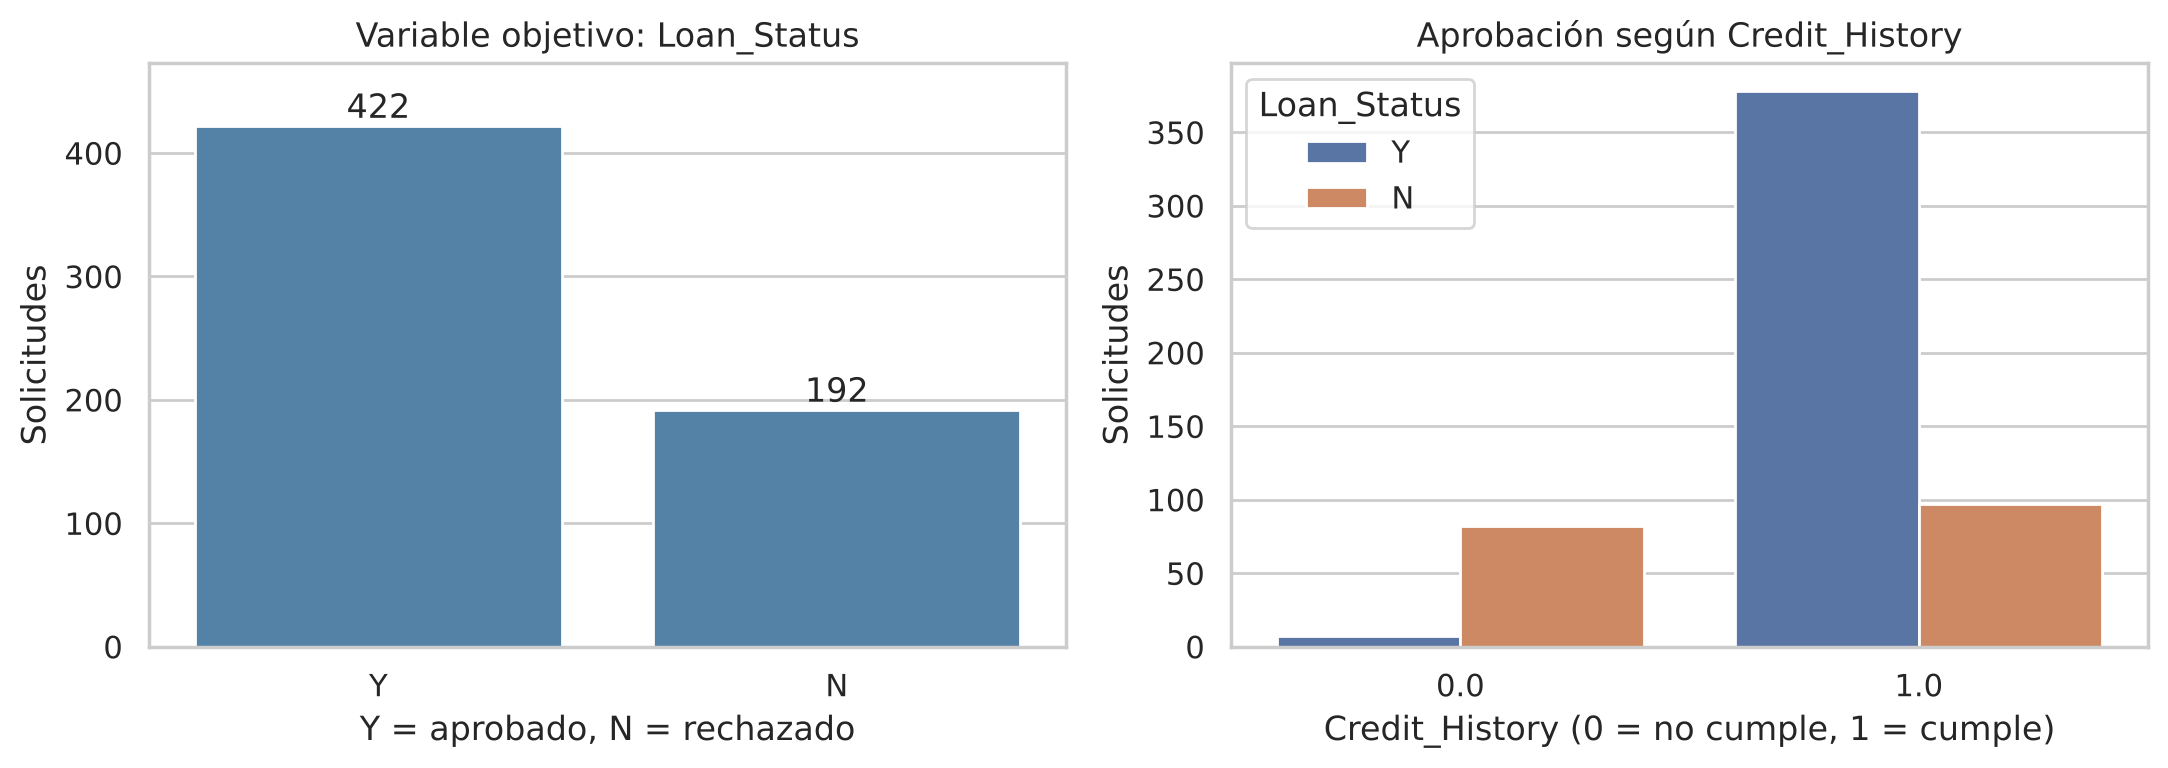

Tasa de aprobación por Credit_History (%):
Credit_History
0.0     7.9
1.0    79.6


In [7]:
df["aprobado"] = (df[TARGET] == "Y").astype(int)   # columna auxiliar solo para graficar

# Gráfico 1: balance de la variable objetivo y relación con el historial crediticio
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x=TARGET, order=["Y", "N"], color="steelblue", ax=axes[0])
axes[0].bar_label(axes[0].containers[0])
axes[0].margins(y=0.12)
axes[0].set_title("Variable objetivo: Loan_Status")
axes[0].set_xlabel("Y = aprobado, N = rechazado")
axes[0].set_ylabel("Solicitudes")

sns.countplot(data=df, x="Credit_History", hue=TARGET, hue_order=["Y", "N"], ax=axes[1])
axes[1].set_title("Aprobación según Credit_History")
axes[1].set_xlabel("Credit_History (0 = no cumple, 1 = cumple)")
axes[1].set_ylabel("Solicitudes")

plt.tight_layout()
plt.show()

print("Tasa de aprobación por Credit_History (%):")
print((df.groupby("Credit_History")["aprobado"].mean() * 100).round(1).to_string())

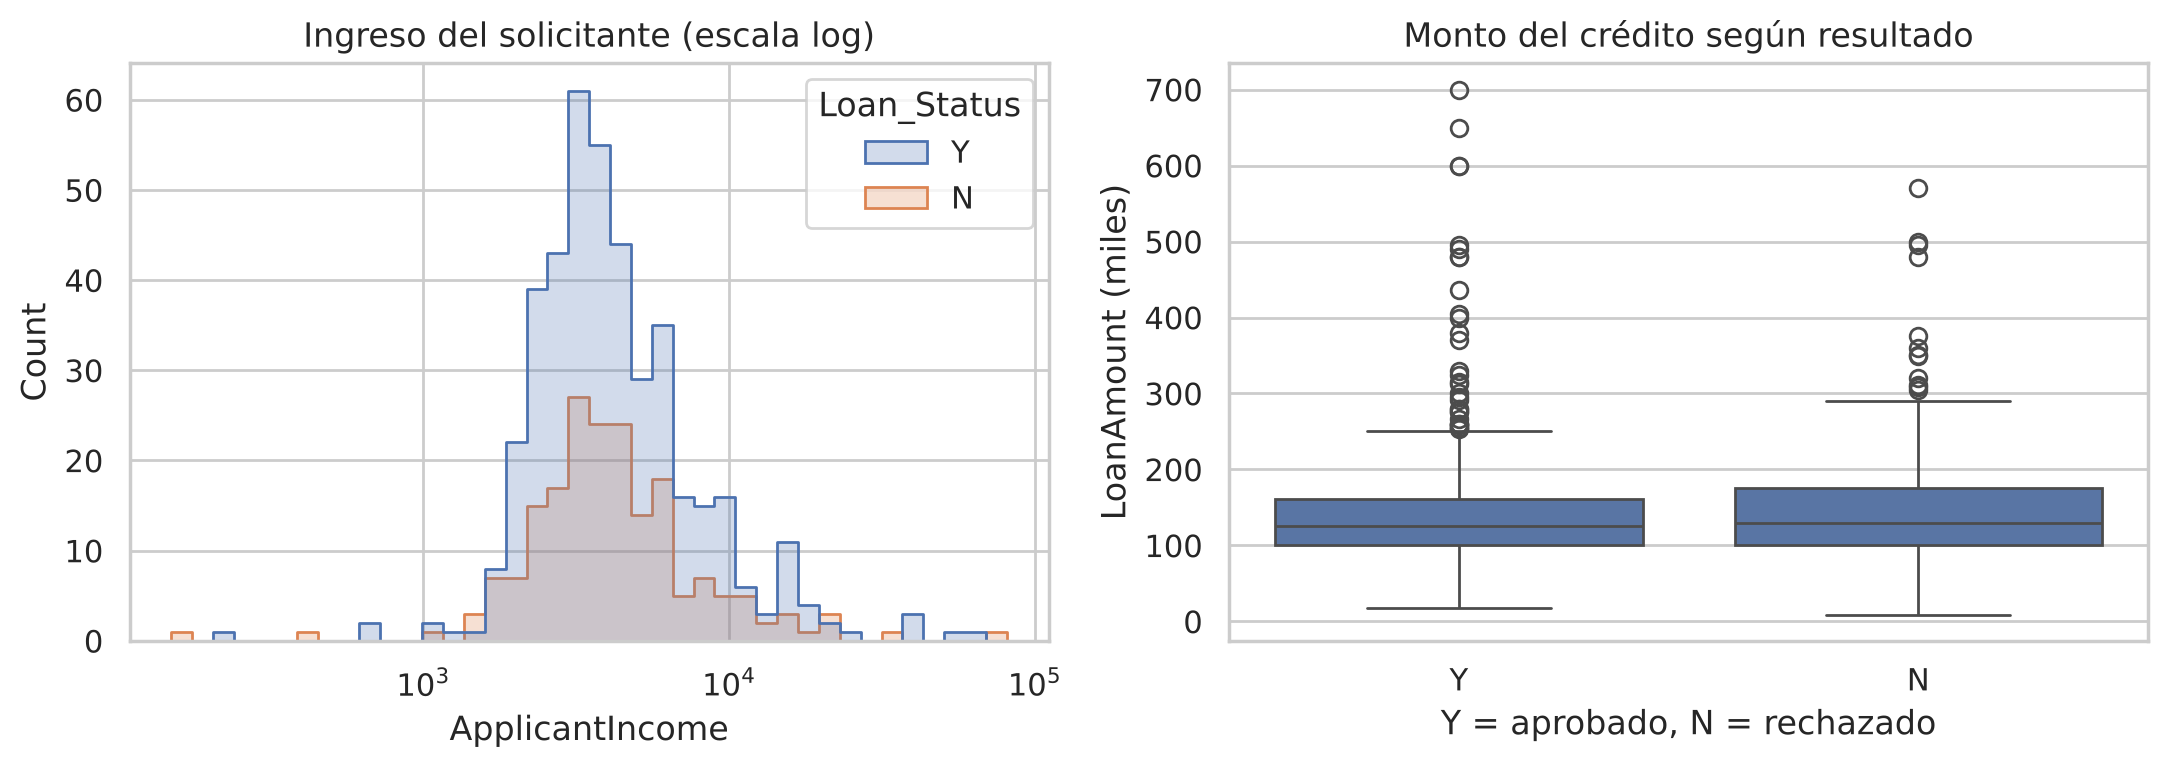

In [8]:
# Gráfico 2: ingresos y monto del crédito según el resultado
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(data=df, x="ApplicantIncome", hue=TARGET, hue_order=["Y", "N"],
             bins=40, log_scale=True, element="step", ax=axes[0])
axes[0].set_title("Ingreso del solicitante (escala log)")
axes[0].set_xlabel("ApplicantIncome")

sns.boxplot(data=df, x=TARGET, y="LoanAmount", order=["Y", "N"], ax=axes[1])
axes[1].set_title("Monto del crédito según resultado")
axes[1].set_xlabel("Y = aprobado, N = rechazado")
axes[1].set_ylabel("LoanAmount (miles)")

plt.tight_layout()
plt.show()

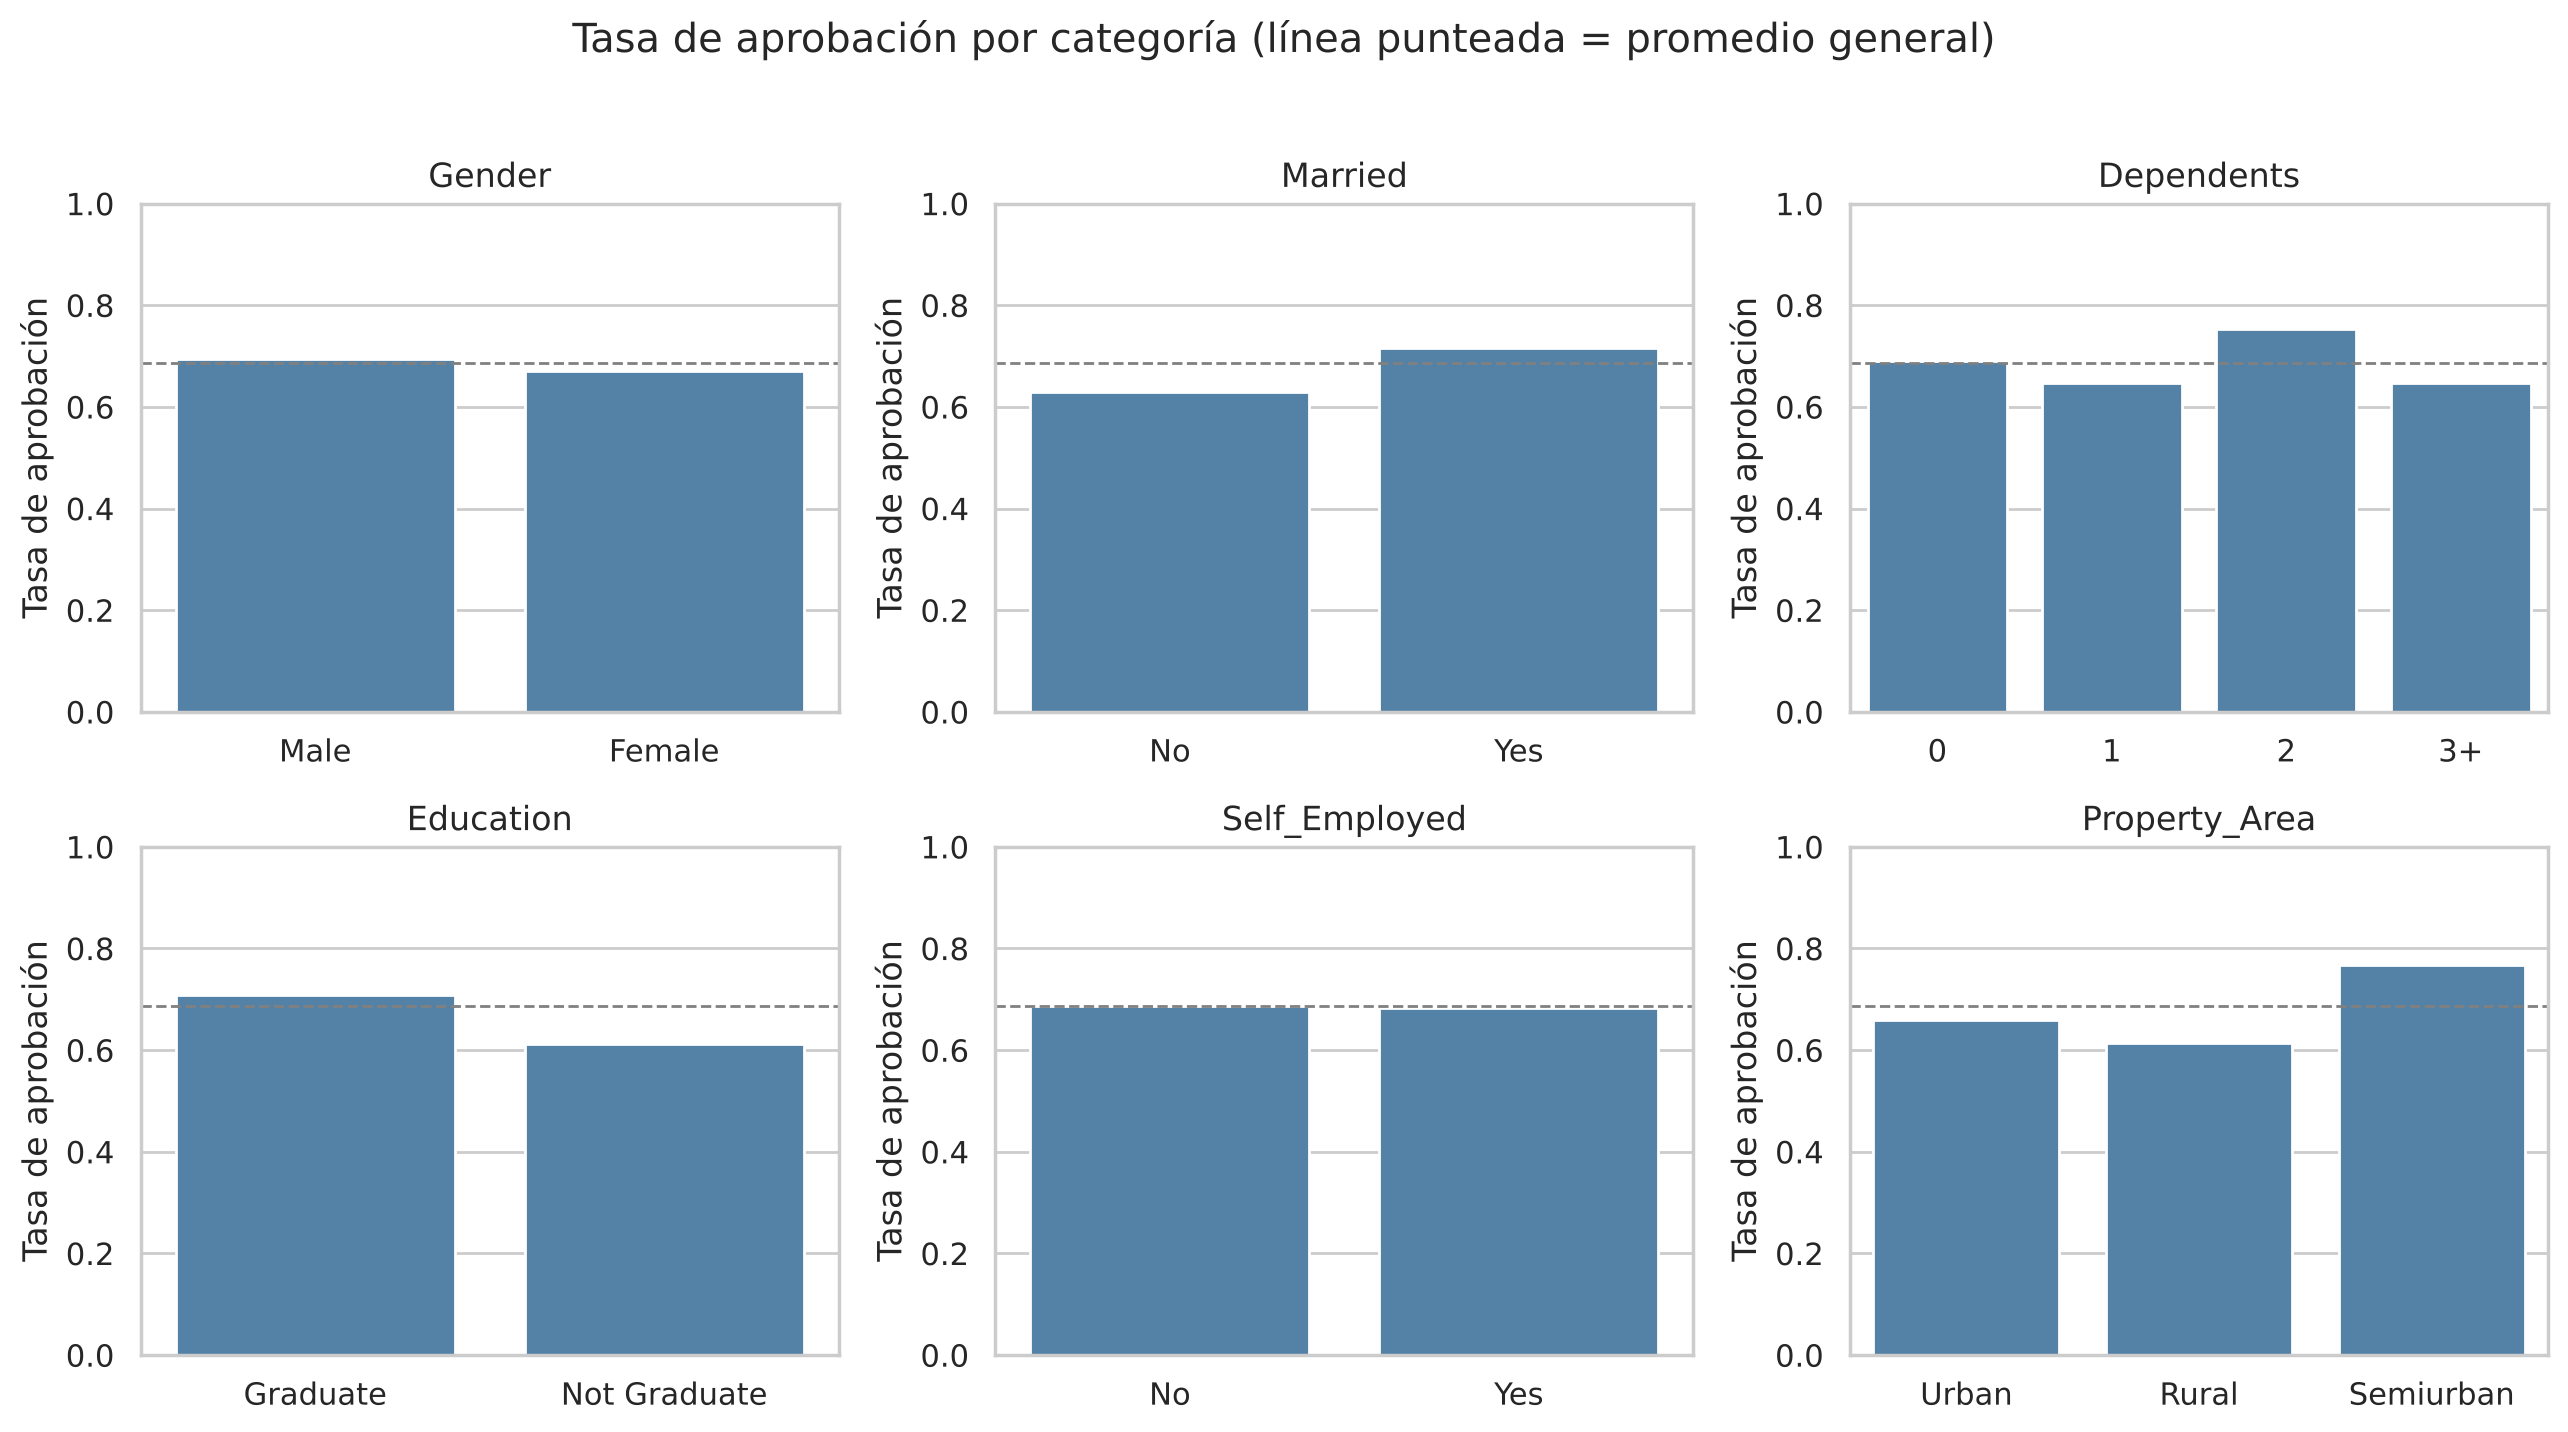

In [9]:
# Gráfico 3: tasa de aprobación por cada variable categórica
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.barplot(data=df, x=col, y="aprobado", errorbar=None, color="steelblue", ax=ax)
    ax.axhline(df["aprobado"].mean(), color="gray", linestyle="--", linewidth=1)
    ax.set_ylim(0, 1)
    ax.set_title(col)
    ax.set_ylabel("Tasa de aprobación")
    ax.set_xlabel("")
fig.suptitle("Tasa de aprobación por categoría (línea punteada = promedio general)", y=1.02)
plt.tight_layout()
plt.show()

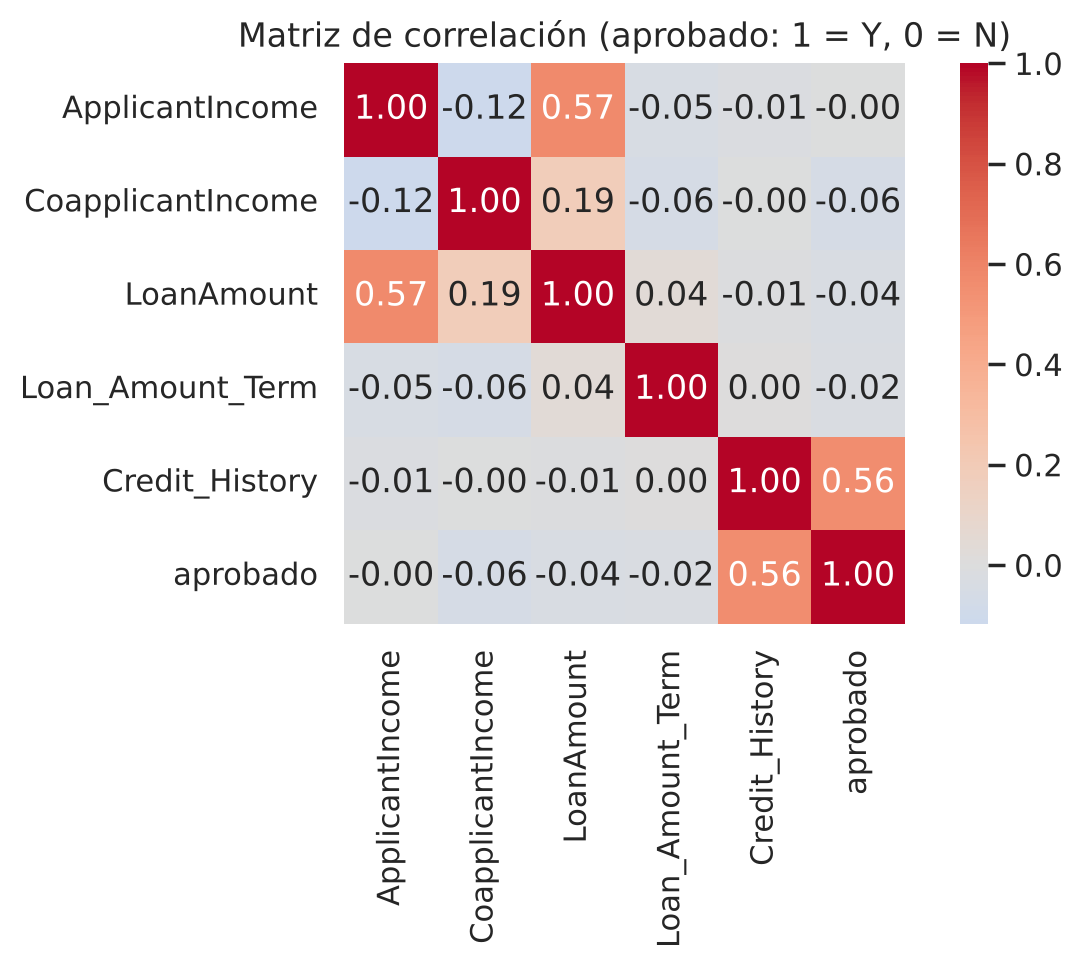

In [10]:
# Gráfico 4: correlación entre variables numéricas y el resultado
corr = df[num_cols + ["aprobado"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlación (aprobado: 1 = Y, 0 = N)")
plt.tight_layout()
plt.show()

df = df.drop(columns="aprobado")   # ya no se necesita

**Lectura rápida del EDA:**
- Hay 149 valores nulos repartidos en 7 columnas; las más afectadas son `Credit_History` (8,1 %) y `Self_Employed` (5,2 %).
- La variable objetivo está desbalanceada: 68,7 % aprobadas (422) y 31,3 % rechazadas (192).
- `Credit_History` es, por lejos, la variable más ligada al resultado: se aprueba el 79,6 % de quienes tienen historial = 1, frente a solo el 7,9 % de quienes tienen 0. Su correlación con el resultado es 0,56; las demás variables numéricas quedan cerca de 0 (|r| < 0,06).
- Los ingresos y el monto del crédito, por sí solos, casi no separan aprobados de rechazados (la mediana de ingreso es ≈ 3 800 en ambos grupos).
- Entre las categóricas las diferencias son modestas: zona semiurbana 76,8 % vs rural 61,5 %; casados 71,6 % vs no casados 62,9 %; graduados 70,8 % vs no graduados 61,2 %.

## Parte 3 – Preparación de datos

Pasos

1. **Separar `X` (predictoras) e `y` (objetivo)**, convirtiendo `y` a 1 = aprobado, 0 = rechazado. Se descarta `Loan_ID`.
2. **Dividir en entrenamiento y prueba (80 / 20)** con `stratify=y`, para que ambos conjuntos mantengan la misma proporción de aprobados.
3. **Valores faltantes:** se imputan *después* de dividir, usando solo estadísticas del conjunto de entrenamiento. Así el conjunto de prueba no "se cuela" en el preprocesamiento (fuga de datos).
   - Numéricas (incluida `Credit_History`): **mediana**. Para `Credit_History` (0/1) y `Loan_Amount_Term`, la mediana coincide con el valor más frecuente.
   - Categóricas: **valor más frecuente (moda)**.
4. **Codificación:** las categóricas pasan a *one-hot* (las binarias quedan en una sola columna) y las numéricas se estandarizan, lo que ayuda a la regresión logística.

In [11]:
# 1) X e y
X = df.drop(columns=["Loan_ID", TARGET])
y = df[TARGET].map({"Y": 1, "N": 0})

# 2) División 80 / 20 estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"% aprobados -> train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

X_train: (491, 11) | X_test: (123, 11)
% aprobados -> train: 68.6% | test: 69.1%


In [12]:
# 3) y 4) Imputación + codificación + escalado
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

# Vista previa de lo que producirá el preprocesamiento (ajustado solo con entrenamiento)
vista = clone(preprocessor).fit(X_train)
X_train_prep = vista.transform(X_train)
nombres = [n.split("__", 1)[1] for n in vista.get_feature_names_out()]

print(f"Nulos antes en X_train   : {int(X_train.isna().sum().sum())}")
print(f"Nulos después en X_train : {int(np.isnan(X_train_prep).sum())}")
print(f"Columnas resultantes     : {X_train_prep.shape[1]}")
print(nombres)

Nulos antes en X_train   : 124
Nulos después en X_train : 0
Columnas resultantes     : 16
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Gender_Male', 'Married_Yes', 'Dependents_0', 'Dependents_1', 'Dependents_2', 'Dependents_3+', 'Education_Not Graduate', 'Self_Employed_Yes', 'Property_Area_Rural', 'Property_Area_Semiurban', 'Property_Area_Urban']


## Parte 4 – Modelado

Se entrenan **dos modelos** con el mismo preprocesamiento (dentro de un `Pipeline`, de modo que todo se ajusta solo con los datos de entrenamiento):

1. **Regresión Logística:** modelo lineal, simple e interpretable.
2. **Random Forest:** conjunto de árboles de decisión, capaz de capturar relaciones no lineales. Se limita su profundidad (`max_depth=5`, `min_samples_leaf=5`) para que no memorice el entrenamiento, dado que el dataset es pequeño.

Además se incluye un modelo base que siempre predice la clase mayoritaria (`Y`). No cuenta como modelo del taller: sirve como punto de referencia para saber si los otros dos realmente aprenden algo.

In [13]:
modelos = {
    "Regresión Logística": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
}

pipelines = {
    nombre: Pipeline([("prep", clone(preprocessor)), ("modelo", m)])
    for nombre, m in modelos.items()
}
for nombre, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"{nombre}: entrenado con {len(X_train)} solicitudes")

# Modelo base (referencia): siempre predice la clase mayoritaria
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

Regresión Logística: entrenado con 491 solicitudes


Random Forest: entrenado con 491 solicitudes


## Parte 5 – Evaluación del modelo

Todas las métricas se calculan sobre el conjunto de prueba (123 solicitudes que los modelos no vieron). La clase positiva es aprobado (1):
- **Accuracy:** proporción de predicciones correctas.
- **Precision:** de las solicitudes que el modelo dijo "aprobar", cuántas realmente se aprobaron.
- **Recall:** de las que realmente se aprobaron, cuántas detectó el modelo.
- **F1-score:** promedio armónico entre precision y recall.

In [14]:
def evaluar(modelo, X_eval, y_eval):
    y_pred = modelo.predict(X_eval)
    return {
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, zero_division=0),
        "F1-score": f1_score(y_eval, y_pred, zero_division=0),
    }

filas = {"Modelo base (siempre 'Y')": evaluar(base, X_test, y_test)}
for nombre, pipe in pipelines.items():
    filas[nombre] = evaluar(pipe, X_test, y_test)

resultados = pd.DataFrame(filas).T.round(3)
resultados

,Accuracy,Precision,Recall,F1-score
Modelo base (siempre 'Y'),0.691,0.691,1.000,0.817
Regresión Logística,0.862,0.840,0.988,0.908
Random Forest,0.854,0.832,0.988,0.903


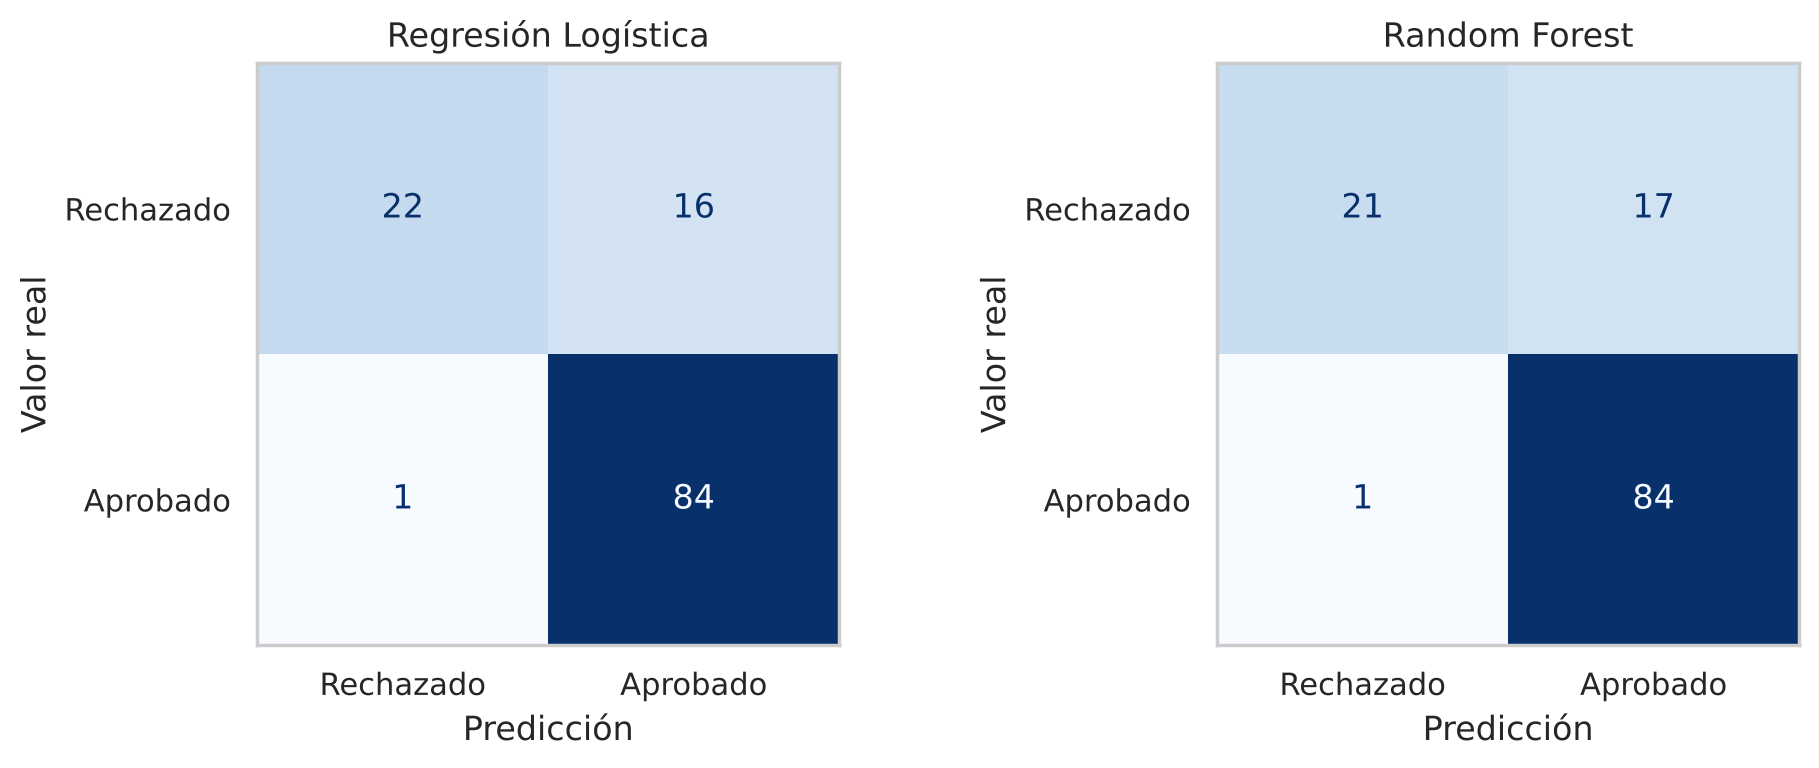

Regresión Logística: verdaderos rechazados=22, falsos aprobados=16, falsos rechazados=1, verdaderos aprobados=84


Random Forest: verdaderos rechazados=21, falsos aprobados=17, falsos rechazados=1, verdaderos aprobados=84


In [15]:
# Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, pipe) in zip(axes, pipelines.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pipe.predict(X_test),
        display_labels=["Rechazado", "Aprobado"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.grid(False)
plt.tight_layout()
plt.show()

for nombre, pipe in pipelines.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pipe.predict(X_test)).ravel()
    print(f"{nombre}: verdaderos rechazados={tn}, falsos aprobados={fp}, "
          f"falsos rechazados={fn}, verdaderos aprobados={tp}")

**Chequeo de estabilidad (validación cruzada, 5 folds sobre el entrenamiento).** Con solo 123 solicitudes de prueba, un único resultado puede ser optimista o pesimista por azar. La validación cruzada muestra qué tan estable es el desempeño.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for nombre, pipe in pipelines.items():
    acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    print(f"{nombre}: accuracy = {acc.mean():.3f} ± {acc.std():.3f} | F1 = {f1.mean():.3f} ± {f1.std():.3f}")

Regresión Logística: accuracy = 0.798 ± 0.044 | F1 = 0.870 ± 0.026


Random Forest: accuracy = 0.798 ± 0.046 | F1 = 0.870 ± 0.027


## Parte 6 – Interpretación

Para saber qué variables pesan más se usa importancia por permutación: se desordena una variable a la vez en el conjunto de prueba y se mide cuánto cae la *accuracy*. Si cae mucho, el modelo dependía de esa variable. Se aplica sobre las variables originales (no sobre las columnas one-hot), lo que facilita la lectura.

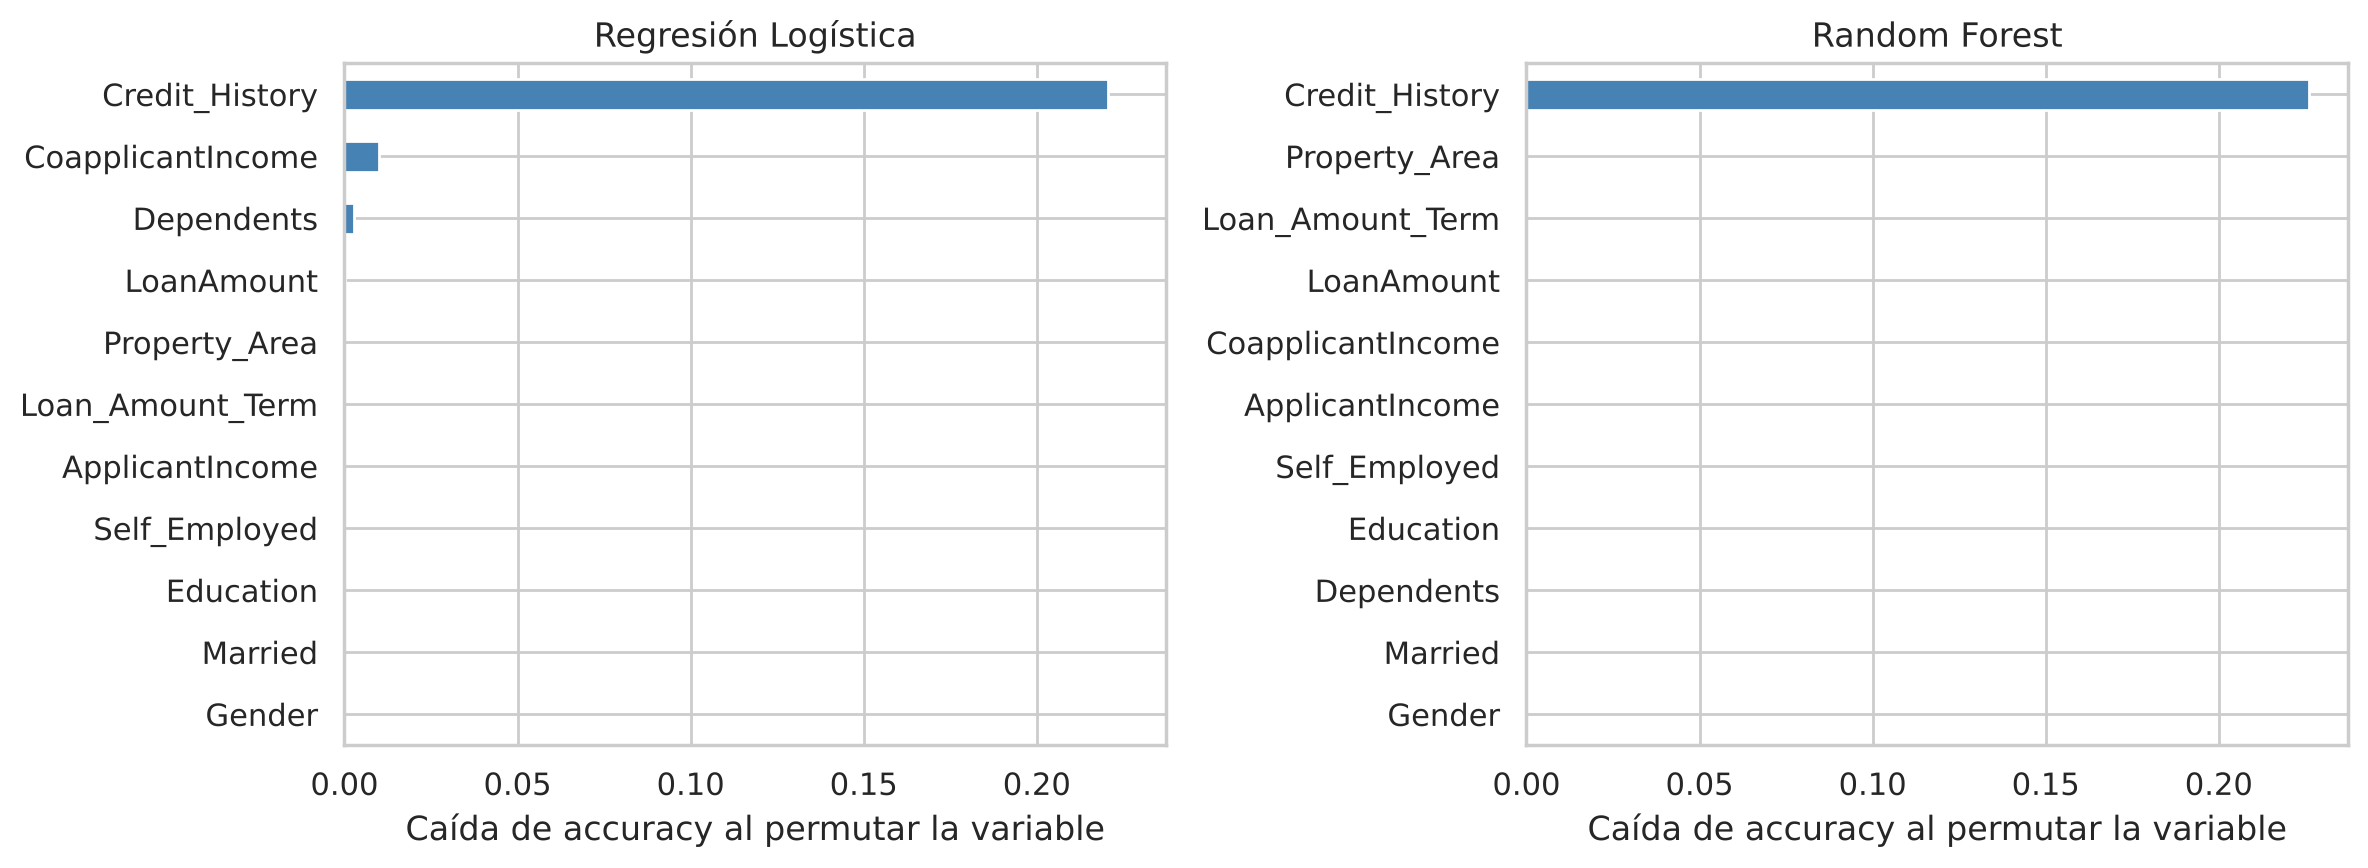

,Regresión Logística,Random Forest
ApplicantIncome,0.000,0.000
CoapplicantIncome,0.010,0.000
Credit_History,0.221,0.226
Dependents,0.003,0.000
Education,0.000,0.000
Gender,0.000,0.000
LoanAmount,0.000,0.000
Loan_Amount_Term,0.000,0.000
Married,0.000,0.000
Property_Area,0.000,0.000


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
importancias = {}
for ax, (nombre, pipe) in zip(axes, pipelines.items()):
    r = permutation_importance(
        pipe, X_test, y_test, scoring="accuracy",
        n_repeats=30, random_state=RANDOM_STATE,
    )
    imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values()
    importancias[nombre] = imp.sort_values(ascending=False)
    imp.plot.barh(ax=ax, color="steelblue")
    ax.set_title(nombre)
    ax.set_xlabel("Caída de accuracy al permutar la variable")
plt.tight_layout()
plt.show()

pd.DataFrame(importancias).round(3)

In [18]:
# Dirección del efecto en la regresión logística (variables ya estandarizadas)
logit = pipelines["Regresión Logística"]
coef = pd.Series(
    logit.named_steps["modelo"].coef_[0],
    index=[n.split("__", 1)[1] for n in logit.named_steps["prep"].get_feature_names_out()],
).sort_values(key=abs, ascending=False)

print("Coeficientes de la regresión logística (positivo = favorece la aprobación):")
coef.round(3).to_frame("coeficiente")

Coeficientes de la regresión logística (positivo = favorece la aprobación):


,coeficiente
Credit_History,1.246
Married_Yes,0.532
Property_Area_Semiurban,0.463
Dependents_1,-0.386
Education_Not Graduate,-0.371
Dependents_2,0.320
Property_Area_Rural,-0.312
Self_Employed_Yes,-0.208
Gender_Male,-0.166
Property_Area_Urban,-0.152


### 1. ¿Qué tan bueno es el modelo?

Es útil, ambos modelos aprenden algo real, aunque no son para tomar decisiones solos.

- **Frente al modelo base:** en el conjunto de prueba la regresión logística logra 86,2 % de accuracy (precision 84,0 %, recall 98,8 %, F1 0,908) y el Random Forest 85,4 % (precision 83,2 %, recall 98,8 %, F1 0,903). El modelo base que siempre dice "aprobado" obtiene 69,1 %, así que ambos mejoran unos 16 puntos.
- **Hay que leer ese 86 % con cautela:** la validación cruzada sobre el entrenamiento da cerca de 80 % de accuracy (± 4,5 puntos) para ambos modelos, y el conjunto de prueba tiene solo 123 solicitudes (un acierto de más o de menos mueve la accuracy casi un punto). Una expectativa realista es alrededor de 80 %.
- **Fortaleza:** el recall de 98,8 % indica que casi nunca rechazan por error una solicitud que sí fue aprobada (solo 1 de 85).
- **Debilidad:** de las 38 solicitudes que realmente fueron rechazadas, la regresión logística detecta 22 (58 %) y el Random Forest 21 (55 %); el resto las marca como aprobadas (16 y 17 "falsos aprobados"). En un banco este es el error más costoso, y es la razón por la que la precision queda en torno a 84 %.
- **Entre los dos modelos no hay diferencia real:** la distancia es de una sola predicción sobre 123. Por ser más simple e interpretable, la regresión logística es la opción preferible.

### 2. ¿Qué variable parece influir más en la predicción?

`Credit_History` (historial crediticio), con mucha ventaja. Al desordenarla, la accuracy cae unos 22 puntos en ambos modelos (0,221 en la regresión logística y 0,226 en el Random Forest); con cualquier otra variable la caída es prácticamente cero (la mayor es `CoapplicantIncome` con 0,010 en la regresión logística).

Esto coincide con el EDA (79,6 % de aprobación con buen historial frente a 7,9 % sin él) y con la regresión logística, donde `Credit_History` tiene el coeficiente positivo más grande: tener buen historial favorece la aprobación. Variables como estar casado o vivir en zona semiurbana también empujan hacia la aprobación en la regresión logística, pero su aporte medible en la prueba es casi nulo.

En la práctica, los modelos replican casi la regla "si tiene buen historial crediticio, se aprueba". Eso explica la debilidad anterior: alrededor del 20 % de quienes tienen historial = 1 igual fueron rechazados, y las demás variables disponibles no explican bien por qué.

### Limitaciones
- El dataset es pequeño (614 filas): las métricas tienen margen de error y pueden variar con otra división.
- No se ajustaron hiperparámetros ni se probaron más modelos; el taller pide un flujo básico.
- Las 50 solicitudes sin `Credit_History` se imputaron con 1 (la mediana). Es una suposición razonable (el 74 % de ellas fue aprobada), pero no es información real, y esta es la variable más influyente.
- Variables como `Gender` o `Married` podrían introducir sesgos si se usaran en un sistema real de crédito; aquí se mantienen solo porque forman parte del dataset del ejercicio.